In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv"

In [144]:
!curl -o data.csv $data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  954k  100  954k    0     0  2753k      0 --:--:-- --:--:-- --:--:-- 2758k


In [181]:
df = pd.read_csv('data.csv')

## Data Prepration

In [182]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [183]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [184]:
df.isnull().any()

customerID          False
gender              False
SeniorCitizen       False
Partner             False
Dependents          False
tenure              False
PhoneService        False
MultipleLines       False
InternetService     False
OnlineSecurity      False
OnlineBackup        False
DeviceProtection    False
TechSupport         False
StreamingTV         False
StreamingMovies     False
Contract            False
PaperlessBilling    False
PaymentMethod       False
MonthlyCharges      False
TotalCharges        False
Churn               False
dtype: bool

In [185]:
str_col = list(df.select_dtypes(include=['object', 'string']).columns)
num_col = list(df.select_dtypes(include=['number']).columns)

na_col = list(df[str_col].columns[df[str_col].isnull().any()])
na_num_col = list(df[num_col].columns[df[num_col].isnull().any()])

df[na_num_col] = df[na_num_col].fillna(0) # In parallel => faster than loops
df[na_col] = df[na_col].fillna("NA")

In [186]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [187]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'string'].index)
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')
    df[c] = df[c].str.lower().str.replace('-', '_')

In [188]:
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590_vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month_to_month,yes,electronic_check,29.85,29.85,no
1,5575_gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.5,no
2,3668_qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month_to_month,yes,mailed_check,53.85,108.15,yes
3,7795_cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,no
4,9237_hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month_to_month,yes,electronic_check,70.70,151.65,yes


In [189]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')

In [190]:
df.totalcharges = df.totalcharges.fillna(0)

In [191]:
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: str

In [192]:
df.churn = (df.churn == 'yes').astype(int)

In [193]:
df.churn.head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

## Setting up the validation framework

In [194]:
from sklearn.model_selection import train_test_split

In [195]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [196]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [197]:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

In [198]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [199]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [200]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

## EDA

In [202]:
df_full_train = df_full_train.reset_index(drop=True)

In [203]:
df_full_train

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,5442_pptjy,male,0,yes,yes,12,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.70,258.35,0
1,6261_rcvns,female,0,no,no,42,yes,no,dsl,yes,...,yes,yes,no,yes,one_year,no,credit_card_(automatic),73.90,3160.55,1
2,2176_osjuv,male,0,yes,no,71,yes,yes,dsl,yes,...,no,yes,no,no,two_year,no,bank_transfer_(automatic),65.15,4681.75,0
3,6161_erdgd,male,0,yes,yes,71,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,no,electronic_check,85.45,6300.85,0
4,2364_ufrom,male,0,no,no,30,yes,no,dsl,yes,...,no,yes,yes,no,one_year,no,electronic_check,70.40,2044.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,0781_lkxbr,male,1,no,no,9,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month_to_month,yes,electronic_check,100.50,918.60,1
5630,3507_gasnp,male,0,no,yes,60,yes,no,no,no_internet_service,...,no_internet_service,no_internet_service,no_internet_service,no_internet_service,two_year,no,mailed_check,19.95,1189.90,0
5631,8868_wozgu,male,0,no,no,28,yes,yes,fiber_optic,no,...,yes,no,yes,yes,month_to_month,yes,electronic_check,105.70,2979.50,1
5632,1251_krreg,male,0,no,no,2,yes,yes,dsl,no,...,no,no,no,no,month_to_month,yes,mailed_check,54.40,114.10,1


In [206]:
df_full_train.churn.value_counts(normalize=True)    # no. of ones = churn rate

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [210]:
# for binary values churn rate can also be calculated by mean (since only 1 will add up and mean give no. of ones / total)
global_churn_rate = df_full_train.churn.mean()
round(global_churn_rate, 2)

np.float64(0.27)

In [211]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [212]:
df_full_train.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

In [213]:
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents',
       'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod']

In [214]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

## Feature importance: Churn rate and risk ratio

**Churn rate**

In [215]:
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()
churn_female

np.float64(0.27682403433476394)

In [216]:
churn_male = df_full_train[df_full_train.gender == 'male'].churn.mean()
churn_male

np.float64(0.2632135306553911)

In [217]:
df_full_train.partner.value_counts()

partner
no     2932
yes    2702
Name: count, dtype: int64

In [219]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
churn_partner

np.float64(0.20503330866025166)

In [220]:
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()
churn_no_partner

np.float64(0.3298090040927694)

For **gender it does not really matter** much if gender id male or felamle on churn rate, <br>
but churn rate **with partner is way less** then global and **without partner is much more** than global churn rate.

```
Partner variable is more important than gender variable for predicting churn
```

**Risk ratio**

In [221]:
churn_no_partner / global_churn_rate

np.float64(1.2216593879412643)

In [222]:
churn_partner / global_churn_rate

np.float64(0.7594724924338315)

### Make it for automatic for all variables

In [223]:
from IPython.display import display

In [226]:
for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn_rate
    df_group['risk'] = df_group['mean'] / global_churn_rate
    display(df_group)
    print()
    print()

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980




seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208




partner


...

,mean,count,diff,risk
contract,,,,
month_to_month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730




paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560




paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


## Feature importance: Mutual information
Mutual Information (MI) is a metric from information theory that measures how much knowing the value of one variable reduces uncertainty about another variable.

In [227]:
from sklearn.metrics import mutual_info_score

In [228]:
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [229]:
mutual_info_score(df_full_train.churn, df_full_train.gender)

0.0001174846211139946

In [230]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [234]:
mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

## Feature importance: Correlation
**-1<r<1** <br>
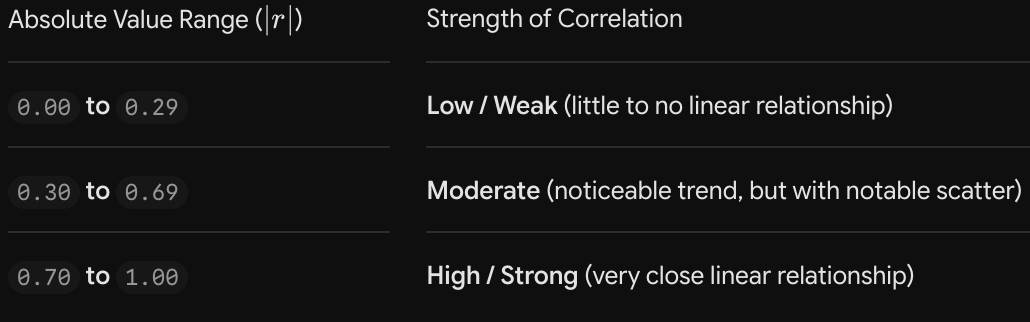{width=500px}

In [235]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

## One-hot encoding

In [237]:
from sklearn.feature_extraction import DictVectorizer

In [238]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')

In [240]:
dv = DictVectorizer(sparse=False)

In [241]:
X_train = dv.fit_transform(train_dicts)

In [242]:
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

In [243]:
X_val = dv.transform(val_dicts)

## Logistic regression

In [244]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

```py
def linear_regression(xi) :
    result = w0
    for j in range(len(w)):
        result = result + xi[j] * w[j]
        
    return result

def logistic_regression(xi):
    score = w0
    for j in range(len(w)):
        score = score + xi[j] * w[j]

    result = sigmoid(score)

    return result
```

## Training logistic regression with Scikit-Learn

In [289]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [290]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.fit_transform(X_val)

In [291]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [292]:
y_pred = model.predict_proba(X_val_scaled)[:, 1]

In [293]:
churn_decision = (y_pred >= 0.5).astype(int)

In [294]:
(y_val == churn_decision).mean()

np.float64(0.8048261178140526)

In [295]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision
df_pred['actual'] = y_val

In [296]:
df_pred['correct'] = df_pred.prediction == df_pred.actual

In [297]:
df_pred

,probability,prediction,actual,correct
0,0.006469,0,0,True
1,0.195882,0,0,True
2,0.208805,0,0,True
3,0.562860,1,1,True
4,0.207985,0,0,True
...,...,...,...,...
1404,0.297359,0,0,True
1405,0.040908,0,1,False
1406,0.151917,0,0,True
1407,0.790774,1,1,True


In [298]:
df_pred.correct.mean()

np.float64(0.8048261178140526)

## Model interpretation

In [300]:
dv.get_feature_names_out()

array(['contract=month_to_month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [302]:
model.coef_

array([[ 0.30309007, -0.02061425, -0.33378214,  0.01613003, -0.01613003,
         0.0407251 , -0.08956164,  0.03581534,  0.00973376, -0.00973376,
        -0.28154356,  0.34418286, -0.08956164, -0.62340359, -0.09284431,
         0.00922449,  0.08823976,  0.04256004, -0.08956164,  0.03397329,
         0.11948886, -0.08956164, -0.05008512, -0.08905438,  0.08905438,
        -0.03093909,  0.03093909, -0.02987026, -0.00920366,  0.0419682 ,
        -0.00867674,  0.00922449, -0.00922449,  0.07166185, -0.06578364,
        -0.08956164,  0.14219327, -0.04617135, -0.08956164,  0.12281526,
         0.09674746, -0.08956164, -0.0246452 , -1.58577365,  0.79487953]])

In [303]:
model.coef_[0].round(3)

array([ 0.303, -0.021, -0.334,  0.016, -0.016,  0.041, -0.09 ,  0.036,
        0.01 , -0.01 , -0.282,  0.344, -0.09 , -0.623, -0.093,  0.009,
        0.088,  0.043, -0.09 ,  0.034,  0.119, -0.09 , -0.05 , -0.089,
        0.089, -0.031,  0.031, -0.03 , -0.009,  0.042, -0.009,  0.009,
       -0.009,  0.072, -0.066, -0.09 ,  0.142, -0.046, -0.09 ,  0.123,
        0.097, -0.09 , -0.025, -1.586,  0.795])

In [304]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=month_to_month': np.float64(0.303),
 'contract=one_year': np.float64(-0.021),
 'contract=two_year': np.float64(-0.334),
 'dependents=no': np.float64(0.016),
 'dependents=yes': np.float64(-0.016),
 'deviceprotection=no': np.float64(0.041),
 'deviceprotection=no_internet_service': np.float64(-0.09),
 'deviceprotection=yes': np.float64(0.036),
 'gender=female': np.float64(0.01),
 'gender=male': np.float64(-0.01),
 'internetservice=dsl': np.float64(-0.282),
 'internetservice=fiber_optic': np.float64(0.344),
 'internetservice=no': np.float64(-0.09),
 'monthlycharges': np.float64(-0.623),
 'multiplelines=no': np.float64(-0.093),
 'multiplelines=no_phone_service': np.float64(0.009),
 'multiplelines=yes': np.float64(0.088),
 'onlinebackup=no': np.float64(0.043),
 'onlinebackup=no_internet_service': np.float64(-0.09),
 'onlinebackup=yes': np.float64(0.034),
 'onlinesecurity=no': np.float64(0.119),
 'onlinesecurity=no_internet_service': np.float64(-0.09),
 'onlinesecurity=yes': np.flo

## Using the model

In [306]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

In [308]:
dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

In [311]:
scaler = StandardScaler()
X_full_train_scaled = scaler.fit_transform(X_full_train)

In [312]:
y_full_train = df_full_train.churn.values

In [313]:
model = LogisticRegression()
model.fit(X_full_train_scaled, y_full_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [314]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')

In [325]:
X_test = dv.transform(dicts_test)
X_test_scaled = scaler.transform(X_test)

In [326]:
y_pred = model.predict_proba(X_test_scaled)[:, 1]

In [327]:
churn_decision = (y_pred >= 0.5)

In [328]:
(churn_decision == y_test).mean()

np.float64(0.8119233498935415)

Predict

In [340]:
customer = dicts_test[10]
customer

{'gender': 'male',
 'seniorcitizen': 1,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'no',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'no',
 'onlinebackup': 'yes',
 'deviceprotection': 'no',
 'techsupport': 'no',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'month_to_month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'mailed_check',
 'tenure': 32,
 'monthlycharges': 93.95,
 'totalcharges': 2861.45}

In [341]:
X_small = dv.transform([customer])
X_small_scaled = scaler.transform(X_small)

In [342]:
model.predict_proba(X_small_scaled)

array([[0.5155712, 0.4844288]])

In [343]:
y_test[10]

np.int64(0)